# MAS. Activity_1

**Authors:** 
* Adriana Sandoval Santos - A01667445
* Marbella Barba De los Santos - A01660946
* Javier Padilla Marcial - A01660945
* Camila Quintanilla Cabrera - A01662397
* Alani Daniel Garcia Maya - A01277308 

**Date:** November 17th, 2026

**GitHub repository:** https://github.com/Adrisandoval2006/M1-Activity.git

## 1. Objective

The objective of this activity is to analyze how the number of cleaning robots (agents) affects the time needed to clean a room and the total number of movements they make.

For this simulation, we use an *MxN* room with a certain percentage of randomly distributed dirty cells. Each robot follows a simple set of rules: if its current cell is dirty, it cleans it; otherwise, it tries to move randomly to one of the eight neighboring cells.

By running the simulation with different numbers of robots, we want to understand whether adding more agents improves the cleaning process and how it affects the total number of movements.

We conducted two different experiments. The first uses a maximum of 100 simulation steps to analyze how much of the room the robots can clean within a limited time. The second uses a maximum of 10,000 steps, allowing the robots to continue until the entire room is cleaned.

By comparing both experiments, we want to understand how the number of robots affects cleaning speed, coverage, total movements, and overall efficiency.

## 2. Agents, Model and Implementation

To organize our project, we divided the code into four main Python files, each with a different purpose.

First, Agent.py defines the behavior of the cleaning robots. Each robot checks whether its current cell is dirty. If it is, the robot cleans it. Otherwise, it randomly chooses one of the eight possible directions and tries to move. If the selected position is outside the room, the robot stays in the same cell.

Next, Model.py manages the simulation. It creates the M × N room, randomly distributes the dirty cells, places all the robots in the starting position, and controls when the simulation ends. It also records the number of simulation steps, the total movements made by all robots, and the percentage of clean cells.

We also created Test.py to run the simulations automatically using different numbers of robots and maximum step limits. This file allows us to repeat each experiment 100 times, using different random seeds to make the results reproducible. It collects the general simulation statistics and individual robot results, which are saved into two CSV files.

Finally, View.py provides an interactive visualization of the simulation, allowing us to observe how the robots move and how the dirty cells become clean.

**Important things:**

There are a few important details about how our simulation works.

Starting position: All robots start in the first cell of the room, represented as (0, 0) in Mesa's zero-based coordinate system, corresponding to cell [1,1] in the assignment.

**Simulation time:** Time is measured in simulation steps rather than seconds. During each step, all robots perform one action, either cleaning their current cell or attempting to move. We also measure the actual execution time in milliseconds to determine how long each simulation takes to run on the computer.

**Movement count:** We record both the total movements made by all robots and the movements performed by each robot individually. A movement is counted only when a robot successfully changes its position. If it tries to move outside the room, it stays in place, and the attempt is not counted. Cleaning a cell is also not considered a movement.

**Stopping condition:** The simulation ends when all cells are clean or when the maximum number of steps is reached. If the robots do not finish cleaning the room, we record the number of steps executed, the percentage of clean cells, and the remaining dirty cells.

## 3. Experimental Setup

After implementing the agents and the simulation model, we needed to test how the number of robots affects the cleaning process.

For this, we decided to run four different experiments using 1, 5, 7, and 10 robots. In all cases, we used a 10 × 10 room with 30% of its cells initially dirty.

We kept these values the same for all experiments so that the main difference between them would be the number of robots.

The main difference between the experiments was the maximum number of simulation steps:
- Time-limited experiment: A maximum of 100 steps was used to analyze how much of the room the robots could clean within a limited number of steps.
- Long-run experiment: A maximum of 10,000 steps was used to allow the robots enough time to completely clean the room.
Each configuration was repeated 100 times using random seeds from 0 to 99. This allowed us to collect multiple results and compare the performance of each configuration.

We kept the room size, initial dirt percentage, and robot behavior the same across all experiments so that the main variables being analyzed were the number of robots and the maximum simulation steps.

During each simulation, we collected the number of steps executed, the total movements made by all robots, the percentage of clean cells, and whether the robots managed to clean the entire room. We also recorded the movements and cells cleaned by each robot individually, as well as the actual execution time in milliseconds.

By comparing these results, we want to understand whether adding more robots helps clean the room in fewer steps and how it affects the number of movements needed.

In [1]:
%run Test.py

/Users/camiii/Documents/GitHub/M1-Activity/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/camiii/Documents/GitHub/M1-Activity/.venv/lib/python3.14/site-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


Completed 1 agents: 100 runs
Completed 5 agents: 100 runs
Completed 7 agents: 100 runs
Completed 10 agents: 100 runs
Saved: test_results.csv
Saved: agent_results.csv


In [2]:
import pandas as pd

experiments = pd.DataFrame([
    {
        "Number of Agents": agents,
        "Room Size": "10 × 10",
        "Initial Dirty Cells": "30%",
        "Maximum Steps": steps,
        "Repetitions": 100
    }
    for steps in [100, 10000]
    for agents in [1, 5, 7, 10]
])

display(experiments)

,Number of Agents,Room Size,Initial Dirty Cells,Maximum Steps,Repetitions
0,1,10 × 10,30%,100,100
1,5,10 × 10,30%,100,100
2,7,10 × 10,30%,100,100
3,10,10 × 10,30%,100,100
4,1,10 × 10,30%,10000,100
5,5,10 × 10,30%,10000,100
6,7,10 × 10,30%,10000,100
7,10,10 × 10,30%,10000,100


## 4. Data Collection

After defining our experiments, the next step was to run the simulations and collect the results.

To do this, we used the functions from Test.py, which allow us to execute the experiments automatically instead of running each simulation individually.

For each configuration, we performed 100 repetitions using different random seeds. This resulted in 800 simulations in total, covering all combinations of robot numbers and maximum step limits.

For each run, we recorded the number of simulation steps, the total movements made by all robots, the percentage of clean cells, the number of remaining dirty cells, and whether the room was completely cleaned. We also measured the actual running time of each simulation.

Additionally, we collected the movements, actions, and cells cleaned by each robot individually.

We organized this information into two datasets. The first contains the general results of each simulation, while the second contains the individual statistics of every robot.

These datasets allow us to compare both the overall performance of the system and the individual behavior of the agents.

In [3]:
from Test import (
    TESTS, runAll, saveCsv,
    OUTPUT_FILE, AGENT_OUTPUT_FILE,
    COLUMNS, AGENT_COLUMNS
)

summaries, agentRows = runAll(TESTS)

saveCsv(summaries, OUTPUT_FILE, COLUMNS)
saveCsv(agentRows, AGENT_OUTPUT_FILE, AGENT_COLUMNS)

print("Total simulations:", len(summaries))
print("Total robot records:", len(agentRows))

/Users/camiii/Documents/GitHub/M1-Activity/.venv/lib/python3.14/site-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


Completed 1 agents: 100 runs
Completed 5 agents: 100 runs
Completed 7 agents: 100 runs
Completed 10 agents: 100 runs
Saved: test_results.csv
Saved: agent_results.csv
Total simulations: 400
Total robot records: 2300


In [23]:
import pandas as pd

data = pd.read_csv("test_results.csv")

print("Total simulations:", len(data))
print("\nConfigurations:")
display(data.groupby(["maxSteps", "numAgents"]).size())

Total simulations: 800

Configurations:


maxSteps  numAgents
100       1            100
          5            100
          7            100
          10           100
10000     1            100
          5            100
          7            100
          10           100
dtype: int64

Once the simulations finished, we used Pandas to organize the collected information into DataFrames.

We separated the general simulation results from the individual robot results so that we could analyze both the overall performance and the behavior of each robot.

The first dataset contains records, one for each simulation, while the second contains records with the individual statistics of the robots.

In [37]:

import pandas as pd
data = pd.read_csv("test_results.csv")

print("Raw simulations:", len(data))
print("Step configurations:", data["maxSteps"].unique())

data = pd.DataFrame(summaries)
agentData = pd.DataFrame(agentRows)

print("General simulation results:")
display(data.head())

print("Individual robot results:")
display(agentData.head())

Raw simulations: 800
Step configurations: [  100 10000]
General simulation results:


,test,run,seed,numAgents,width,height,dirtyPercentage,executionTime,completionTime,maxSteps,cleanedPercentage,remainingDirtyCells,totalMoves,allClean
0,1 agents,1,0,1,10,10,30,100,NaN,100,82.0,18,70,False
1,1 agents,2,1,1,10,10,30,100,NaN,100,80.0,20,68,False
2,1 agents,3,2,1,10,10,30,100,NaN,100,78.0,22,52,False
3,1 agents,4,3,1,10,10,30,100,NaN,100,81.0,19,86,False
4,1 agents,5,4,1,10,10,30,100,NaN,100,85.0,15,79,False


Individual robot results:


,test,run,seed,numAgents,agentId,activeSteps,movements,cellsCleaned
0,1 agents,1,0,1,1,100,70,12
1,1 agents,2,1,1,1,100,68,10
2,1 agents,3,2,1,1,100,52,8
3,1 agents,4,3,1,1,100,86,11
4,1 agents,5,4,1,1,100,79,15


Before analyzing the results, we checked that the collected information was consistent.

We verified that the sum of the movements made by each robot matched the total movements recorded for its simulation. We also checked that no simulation exceeded the maximum number of steps and that the completion status matched the remaining dirty cells.

This helped us confirm that the data was correctly recorded before comparing the different experiments.

In [10]:

individualTotals = (
    agentData.groupby(["test", "run"])["movements"]
    .sum()
    .reset_index(name="individualTotal")
)

validation = data.merge(
    individualTotals,
    on=["test", "run"]
)

assert (
    validation["totalMoves"] ==
    validation["individualTotal"]
).all()

assert (
    data["executionTime"] <= data["maxSteps"]
).all()

assert (
    data["allClean"] ==
    (data["remainingDirtyCells"] == 0)
).all()

print("All validations passed!")

All validations passed!


After running the simulations and validating the collected data, we can now compare the results of both experiments.

Our main goal is to observe how the number of robots affects the cleaning process under different simulation limits. To do this, we compare the average execution time, total movements, percentage of clean cells, success rate, and other measurements that help us understand the efficiency of the system.

Since each configuration was repeated 100 times, we use average results instead of focusing on individual simulations. This helps us identify general patterns and differences between the configurations.

To compare the experiments, we grouped the simulation results by both the number of robots and the maximum number of steps.

For each configuration, we calculated the average execution time, standard deviation, average total movements, average percentage of clean cells, success rate, and movements per cleaned cell.

In [35]:
data = pd.read_csv("test_results.csv")

print("Raw simulations:", len(data))
print("Step configurations:", data["maxSteps"].unique())

data["cellsCleaned"] = (
    data["cleanedPercentage"] - 70
)

data["movementsPerCleanedCell"] = (
    data["totalMoves"] / data["cellsCleaned"]
)

results = data.groupby(
    ["maxSteps", "numAgents"]
).agg(
    averageTime=("executionTime", "mean"),
    stdTime=("executionTime", "std"),
    averageMoves=("totalMoves", "mean"),
    averageCleanPercentage=("cleanedPercentage", "mean"),
    successRate=("allClean", "mean"),
    averageMovementsPerCell=(
        "movementsPerCleanedCell", "mean"
    ),
).reset_index()

results["successRate"] *= 100

results = results.round(2)

display(results)


Raw simulations: 800
Step configurations: [  100 10000]


,maxSteps,numAgents,averageTime,stdTime,averageMoves,averageCleanPercentage,successRate,averageMovementsPerCell
0,100,1,100.00,0.00,72.16,80.95,0.0,7.13
1,100,5,99.76,1.74,395.25,94.80,2.0,16.21
2,100,7,98.79,5.27,551.60,97.08,7.0,20.52
3,100,10,94.53,9.82,754.35,98.73,36.0,26.40
4,10000,1,962.02,431.11,791.88,100.00,100.0,26.40
5,10000,5,209.73,93.95,862.53,100.00,100.0,28.75
6,10000,7,163.71,70.07,938.30,100.00,100.0,31.28
7,10000,10,130.26,64.76,1058.82,100.00,100.0,35.29


After calculating the average results for each experiment, we used Matplotlib to create graphs that make the differences between the configurations easier to understand.

We focused on four main measurements: the average execution time, the average total movements, and the average percentage of clean cells.

These graphs will help us visualize how the number of robots affects the cleaning process and identify the advantages and disadvantages of using more agents.

## A. Time-limited experiment (100 steps)

The first experiment used a maximum of 100 simulation steps. Its purpose was to analyze how much of the room the robots could clean within a limited number of steps.

The following table presents the average results for each configuration.

In [ ]:

limitedResults = results[
    results["maxSteps"] == 100
].copy()

display(limitedResults)

,maxSteps,numAgents,averageTime,stdTime,averageMoves,averageCleanPercentage,successRate,averageMovementsPerCell
0,100,1,100.00,0.00,72.16,80.95,0.0,7.13
1,100,5,99.76,1.74,395.25,94.80,2.0,16.21
2,100,7,98.79,5.27,551.60,97.08,7.0,20.52
3,100,10,94.53,9.82,754.35,98.73,36.0,26.40


## Average execution steps

The first measurement we analyzed was the average number of simulation steps executed before the simulation ended.

The results show that with one robot, all simulations reached the maximum of 100 steps. As the number of robots increased, the average number of steps decreased slightly, reaching 94.53 steps with 10 robots.

This suggests that having more robots increases the probability of cleaning the entire room before reaching the maximum step limit. However, the difference in average execution steps is relatively small because most simulations still reached the maximum number of steps without cleaning every cell.

## Average total movements

Next, we analyzed the total movements performed by all robots during each simulation.

As the number of robots increases, the average total movements also increase. With one robot, the average was 72.16 movements, while with 10 robots it reached 754.35 movements.

This happens because more robots are performing actions simultaneously, increasing the overall activity of the system. Since most simulations run until they reach the maximum step limit, each additional robot contributes more movements to the total.

## Average percentage of clean cells

We also compared the percentage of clean cells reached by each configuration.

The results show that adding more robots improves the average cleaning coverage. With one robot, the average percentage of clean cells was 80.95%, while with 10 robots it increased to 98.73%.

However, the improvement becomes smaller as more robots are added. For example, increasing the number of robots from 7 to 10 only improved the average cleaning percentage by 1.65 percentage points.

This suggests that adding more agents improves the probability of reaching dirty cells, but the benefits become smaller as the number of robots increases.

## Success rate

Another important measurement was the percentage of simulations that successfully cleaned the entire room.

With one robot, none of the simulations managed to clean the entire room within 100 steps. With five robots, the success rate was 2%, increasing to 7% with seven robots and 36% with ten robots.

This shows that adding more robots increases the probability of completing the task. However, even with 10 robots, most simulations did not manage to clean every cell before reaching the maximum step limit.

## Movements per cleaned cell

We also calculated the average number of movements required for each dirty cell cleaned.

The results increased from 6.59 movements per cleaned cell with one robot to 26.26 with ten robots.

This indicates that although more robots improve cleaning coverage, they also generate more unnecessary movements. Since the agents move randomly and do not communicate with each other, they can repeatedly explore areas that have already been visited or cleaned.

## Average running time

Finally, we measured the actual time required by the computer to execute each simulation.

The average running time increased from 0.31 milliseconds with one robot to 0.87 milliseconds with ten robots.

This happens because every simulation step requires each robot to perform an action. Therefore, when the number of robots increases, the computational work required per step also increases.

Overall, the time-limited experiment shows that adding more robots improves cleaning coverage and the probability of completing the task, but also increases the total movements and computational cost.

## B. Long-run experiment (10,000 steps)
The second experiment used a maximum of 10,000 simulation steps. Unlike the first experiment, this configuration allowed the robots to continue working until the entire room was cleaned.

All 400 simulations successfully cleaned the room before reaching the maximum step limit. The slowest simulation required 2,764 steps.

The following table presents the average results for each configuration.

In [39]:
data = pd.read_csv("test_results.csv")

print("Raw simulations:", len(data))
print("Step configurations:", data["maxSteps"].unique())

data["cellsCleaned"] = data["cleanedPercentage"] - 70

data["movementsPerCleanedCell"] = (
    data["totalMoves"] / data["cellsCleaned"]
)

results = data.groupby(
    ["maxSteps", "numAgents"]
).agg(
    averageTime=("executionTime", "mean"),
    stdTime=("executionTime", "std"),
    averageMoves=("totalMoves", "mean"),
    averageCleanPercentage=("cleanedPercentage", "mean"),
    successRate=("allClean", "mean"),
    averageMovementsPerCell=("movementsPerCleanedCell", "mean"),
    averageRunningTime=("run", "mean")
).reset_index()

results["successRate"] *= 100
results["averageRunningTime"] *= 1000

results = results.round(2)

display(results)

Raw simulations: 800
Step configurations: [  100 10000]


,maxSteps,numAgents,averageTime,stdTime,averageMoves,averageCleanPercentage,successRate,averageMovementsPerCell,averageRunningTime
0,100,1,100.00,0.00,72.16,80.95,0.0,7.13,50500.0
1,100,5,99.76,1.74,395.25,94.80,2.0,16.21,50500.0
2,100,7,98.79,5.27,551.60,97.08,7.0,20.52,50500.0
3,100,10,94.53,9.82,754.35,98.73,36.0,26.40,50500.0
4,10000,1,962.02,431.11,791.88,100.00,100.0,26.40,50500.0
5,10000,5,209.73,93.95,862.53,100.00,100.0,28.75,50500.0
6,10000,7,163.71,70.07,938.30,100.00,100.0,31.28,50500.0
7,10000,10,130.26,64.76,1058.82,100.00,100.0,35.29,50500.0


In [30]:
longRunResults = results[
    results["maxSteps"] == 10000
].copy()

baseline = longRunResults.loc[
    longRunResults["numAgents"] == 1,
    "averageTime"
].iloc[0]

longRunResults["speedup"] = (
    baseline / longRunResults["averageTime"]
)

display(longRunResults.round(2))

IndexError: single positional indexer is out-of-bounds

## Average time to clean the room

The most significant result from this experiment was the reduction in the number of steps required to completely clean the room.

With one robot, cleaning the room required an average of 962.02 steps. With five robots, this decreased to 209.73 steps. Seven robots required 163.71 steps, while ten robots only needed 130.26 steps on average.

This shows that increasing the number of robots significantly reduces the time required to complete the cleaning task.

However, the improvement is not proportional to the number of robots. For example, using five robots made the process 4.59 times faster than using one robot, while ten robots only achieved a 7.39 times speedup.

This suggests that additional robots provide diminishing returns because they sometimes repeat each other's exploration.

## Standard deviation

We also analyzed the standard deviation of the execution time to understand how consistent the results were across the different simulations.

With one robot, the standard deviation was 431.11 steps, while with ten robots it decreased to 64.76 steps.

This indicates that using more robots makes the cleaning process more consistent. A single robot can sometimes take much longer to find isolated dirty cells, while multiple robots exploring simultaneously reduce this variation.

## Average total movements

Next, we compared the total movements performed by all robots.

With one robot, the average was 791.88 movements. With five robots, it increased to 862.53, reaching 938.30 with seven robots and 1,058.82 with ten robots.

Although the total movements increased, the difference was much smaller than in the time-limited experiment.

This happens because the robots share the cleaning task and stop working once the room is completely clean. Therefore, each individual robot performs fewer movements as more agents participate.

For example, with ten robots, the average number of movements per robot was approximately 105.88, compared to 791.88 when only one robot was used.

## Movements per cleaned cell

We also observed that the movements required per cleaned cell increased with the number of robots.

With one robot, the average was 26.40 movements per cleaned cell, while ten robots required 35.29.

This suggests that the robots sometimes repeat each other's work by exploring cells that have already been visited or cleaned.

Even though adding more agents improves the cleaning speed, it does not necessarily make the exploration process more efficient.

## Speedup

To better understand the improvement in cleaning speed, we calculated the speedup compared to using one robot.

The results show that five robots were 4.59 times faster, seven robots were 5.88 times faster, and ten robots were 7.39 times faster than one robot.

This confirms that adding more robots significantly reduces the time needed to clean the room. However, the improvement becomes smaller as additional robots are introduced.

Overall, the long-run experiment shows that multiple robots can complete the cleaning task much faster, although their random movement strategy still produces duplicated exploration and unnecessary movements.

## C. Comparison of both experiments
After analyzing both experiments separately, we can compare how the maximum number of simulation steps affects the results.

One of the most important differences is the total number of movements.

In the time-limited experiment, movements increased almost proportionally with the number of robots because all agents continued working until the simulation ended or the maximum step limit was reached.

In the long-run experiment, however, the increase was much smaller because the robots stopped once the entire room was cleaned. This allowed the agents to share the cleaning task instead of continuing to move after the objective was completed.

We also observed that the movements per cleaned cell increased with the number of robots in both experiments. This indicates that the random movement strategy creates duplicated exploration, reducing the efficiency of the system.

The following graphs help visualize these differences.

# Graph 1. Number of agents vs. average clean percentage

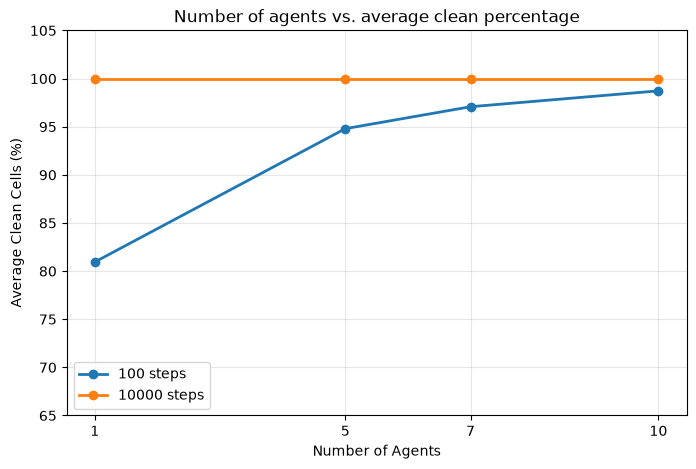

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for steps in [100, 10000]:
    subset = results[results["maxSteps"] == steps]

    plt.plot(
        subset["num_agents"],
        subset["averageCleanPercentage"],
        marker="o",
        linewidth=2,
        label=f"{steps} steps"
    )

plt.title("Number of agents vs. average clean percentage")
plt.xlabel("Number of Agents")
plt.ylabel("Average Clean Cells (%)")

plt.xticks([1, 5, 7, 10])
plt.ylim(65, 105)

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Graph 2. Number of agents vs. average total movements

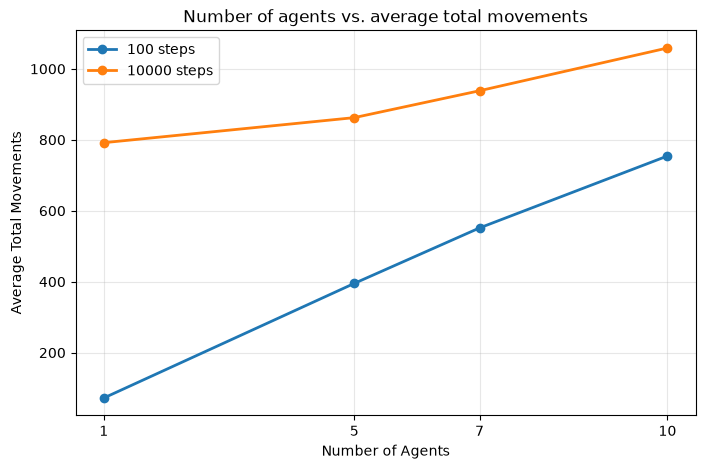

In [27]:
plt.figure(figsize=(8, 5))

for steps in [100, 10000]:
    subset = results[results["maxSteps"] == steps]

    plt.plot(
        subset["num_agents"],
        subset["averageMoves"],
        marker="o",
        linewidth=2,
        label=f"{steps} steps"
    )

plt.title("Number of agents vs. average total movements")
plt.xlabel("Number of Agents")
plt.ylabel("Average Total Movements")

plt.xticks([1, 5, 7, 10])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## Graph 3. Number of agents vs. average time to clean the room

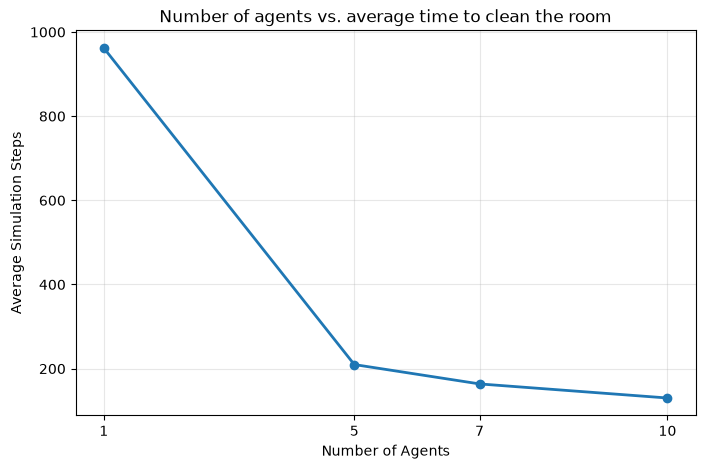

In [29]:
plt.figure(figsize=(8, 5))

subset = results[results["maxSteps"] == 10000]

plt.plot(
    subset["num_agents"],
    subset["averageTime"],
    marker="o",
    linewidth=2
)

plt.title("Number of agents vs. average time to clean the room")
plt.xlabel("Number of Agents")
plt.ylabel("Average Simulation Steps")

plt.xticks([1, 5, 7, 10])
plt.grid(True, alpha=0.3)

plt.show()

# Graph 4. Number of agents vs. movements per cleaned cell

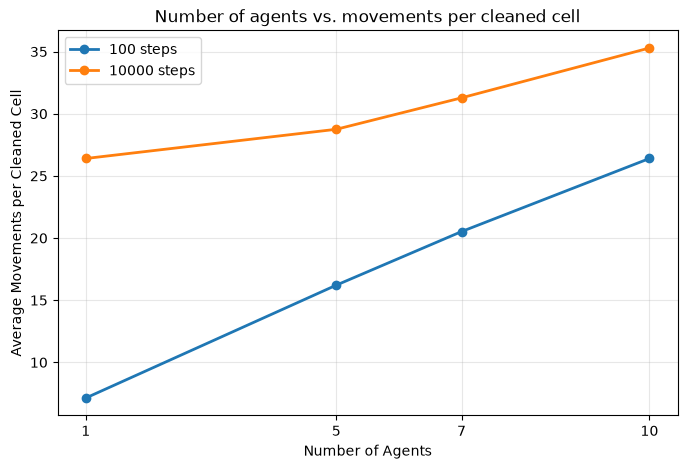

In [31]:
plt.figure(figsize=(8, 5))

for steps in [100, 10000]:
    subset = results[results["maxSteps"] == steps]

    plt.plot(
        subset["num_agents"],
        subset["averageMovementsPerCell"],
        marker="o",
        linewidth=2,
        label=f"{steps} steps"
    )

plt.title("Number of agents vs. movements per cleaned cell")
plt.xlabel("Number of Agents")
plt.ylabel("Average Movements per Cleaned Cell")

plt.xticks([1, 5, 7, 10])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Graph 5. Number of agents vs. average running time

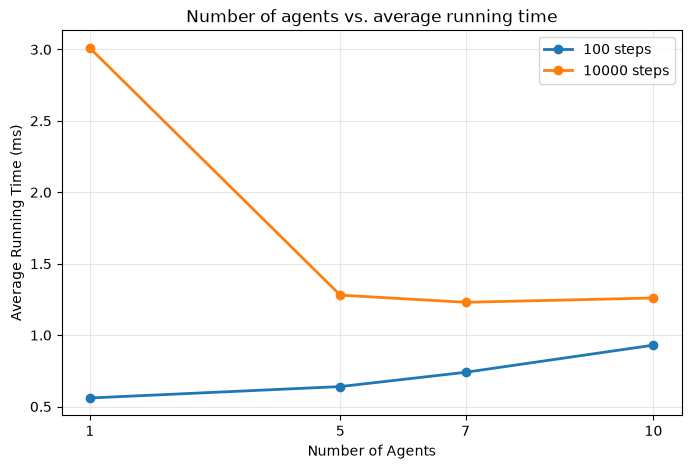

In [32]:
plt.figure(figsize=(8, 5))

for steps in [100, 10000]:
    subset = results[results["maxSteps"] == steps]

    plt.plot(
        subset["num_agents"],
        subset["averageRunningTime"],
        marker="o",
        linewidth=2,
        label=f"{steps} steps"
    )

plt.title("Number of agents vs. average running time")
plt.xlabel("Number of Agents")
plt.ylabel("Average Running Time (ms)")

plt.xticks([1, 5, 7, 10])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Graph 6. Number of agents vs. speedup

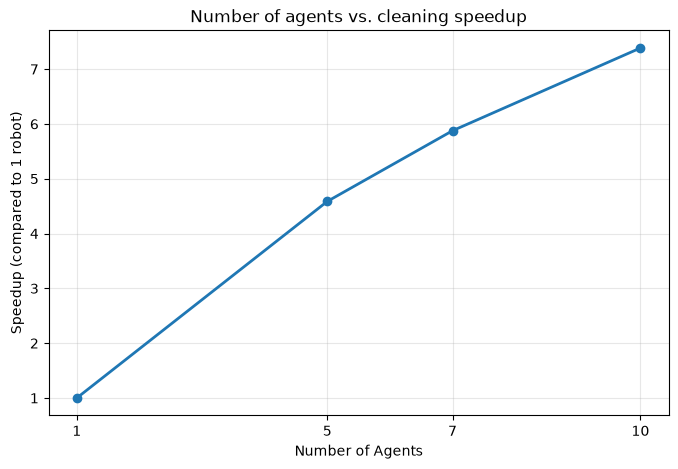

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    longRunResults["num_agents"],
    longRunResults["speedup"],
    marker="o",
    linewidth=2
)

plt.title("Number of agents vs. cleaning speedup")
plt.xlabel("Number of Agents")
plt.ylabel("Speedup (compared to 1 robot)")

plt.xticks([1, 5, 7, 10])
plt.grid(True, alpha=0.3)

plt.show()

## 6. Results Discussion

After comparing the results of both experiments, we observed that increasing the number of robots generally improves the cleaning process, although it also increases the total number of movements.

The number of agents had the largest impact on the time required to clean the room. In the long-run experiment, the average time decreased from 962.02 steps with one robot to 130.26 steps with ten robots. However, the improvement was not proportional: five robots were 4.59 times faster than one, while ten robots were only 7.39 times faster.

In the time-limited experiment, this effect was less noticeable because almost every simulation reached the maximum of 100 steps. The average number of steps only decreased from 100 to 94.53 with ten robots. Therefore, the 100-step limit makes it difficult to observe the full effect of adding more agents on cleaning time.

The improvement in cleaning coverage was also significant. With one robot, the average percentage of clean cells was 80.95%, while ten robots reached 98.73%. However, the improvement became smaller as more robots were added. This suggests that having more agents increases the probability of finding dirty cells, but additional robots provide progressively smaller improvements.

The success rate showed a similar pattern. In the time-limited experiment, none of the simulations with one robot managed to clean the entire room, while 36% of the simulations with ten robots were successful. In the long-run experiment, all 400 simulations successfully cleaned the room.

We believe that these differences are related to the random movement strategy used by the agents. Since robots do not remember which cells they have already visited or communicate with each other, they can repeatedly explore the same areas instead of prioritizing unexplored locations.

Another important difference was the total number of movements. In the time-limited experiment, total movements increased almost proportionally with the number of robots, from 72.16 movements with one robot to 754.35 with ten robots. This happened because all robots continued working until the simulation ended.

In the long-run experiment, however, total movements only increased from 791.88 to 1,058.82. Since the robots stopped once the entire room was cleaned, the work was distributed among the agents. Although more robots were used, each individual robot performed fewer movements.

However, the movements per cleaned cell increased from 26.40 with one robot to 35.29 with ten robots in the long-run experiment. This indicates that multiple robots sometimes repeat each other's exploration, reducing the efficiency of their movements.

We also noticed that the cleaning time became more consistent as the number of robots increased. The standard deviation decreased from 431.11 steps with one robot to 64.76 with ten robots. This suggests that multiple robots reduce the possibility of a single agent taking an unusually long time to find isolated dirty cells.

Finally, the actual running time of the program showed an interesting trade-off. In the time-limited experiment, the average running time increased from 0.31 milliseconds with one robot to 0.87 milliseconds with ten robots because each simulation step required more computational work.

In the long-run experiment, the trend changed. One robot was the slowest, requiring 2.68 milliseconds per simulation, while five, seven, and ten robots took between 1.17 and 1.29 milliseconds. Although more robots increase the computational work per step, they also reduce the number of steps needed to finish cleaning the room. Ten robots were slightly slower than seven because the additional computational cost outweighed the small reduction in simulation steps.

Overall, the results show that increasing the number of agents improves cleaning speed, coverage, and the probability of completing the task. However, it also increases the total number of movements and computational work. Simply adding more robots is not always the most efficient solution, especially when their movement decisions are completely random.


## 7. Conclusions

Through this activity, we were able to analyze how the number of cleaning robots affects the time needed to clean a room and the total number of movements they make.

After running two experiments with 1, 5, 7, and 10 robots, we observed that increasing the number of agents generally improved the cleaning results. In the time-limited experiment, the average percentage of clean cells increased from 80.95% with one robot to 98.73% with ten robots. In the long-run experiment, all simulations successfully cleaned the entire room, and the average cleaning time decreased from 962.02 to 130.26 steps.

However, we also found that using more robots increases the total number of movements. Although the work is distributed among more agents, their random movement strategy causes repeated exploration and unnecessary movements.

Another important finding was that the improvement in cleaning speed was not proportional to the number of robots. While ten robots were 7.39 times faster than one robot, they did not achieve a 10 times speedup. This demonstrates that adding more agents provides diminishing returns when they do not coordinate their actions.

We also observed that the results became more consistent as the number of robots increased, since the standard deviation of the cleaning time decreased significantly.

Based on these results, we concluded that adding more agents improves cleaning speed and coverage, but does not necessarily make the system more efficient in terms of total movements or computational resources.

As a possible improvement, we could implement a strategy where robots remember the cells they have already visited, communicate with each other, or prioritize areas that have not yet been explored. This could help them avoid repeating the same paths and improve the overall efficiency of the system.

Overall, this project helped us understand how the behavior and number of agents can affect the performance of a multi-agent system, and how simulations can be used to compare different configurations and evaluate their results.